# An orbit that gains energy by accident

**Coupled ODEs and conservation laws | Project based on MMP-II Coursework**

A planet orbiting a fixed star should conserve its mechanical energy. Here the planet starts on a slightly elliptical orbit, and four numerical methods solve the *same* equations with the *same* starting conditions. We compare the paths with their energy and angular momentum histories to identify changes caused by numerical integration.

Units: distance in AU, time in years, star's gravitational parameter $\mu=4\pi^2\,\mathrm{AU^3/yr^2}$. The planet is a test particle, so its mass does not enter the calculation. This is a model orbit, not an astronomical ephemeris.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# In AU and years, mu=4*pi**2 makes the circular period at 1 AU equal to 1 year.
mu = 4*np.pi**2

# Start on the positive x axis; the velocity is perpendicular to the radius.
r0 = np.array([1.0, 0.0])

# 90% of circular speed gives a bound ellipse, with this starting point at apocentre.
v0 = np.array([0.0, 0.9*2*np.pi])

# The same step and duration are used for all methods in the main comparison.
dt = 0.025
years = 20

## Model and numerical steps

Writing $\boldsymbol r=(x,y)$ and $\boldsymbol v=(v_x,v_y)$ turns Newton's equation into four first-order equations:

$$\dot{\boldsymbol r}=\boldsymbol v,\qquad \dot{\boldsymbol v}=-\frac{\mu\boldsymbol r}{|\boldsymbol r|^3}.$$

We use explicit Euler, midpoint RK2, classical RK4, and velocity Verlet. Verlet advances position using the old acceleration, then averages the old and new accelerations when updating velocity. The latter requires another force calculation at the new position. All four methods return both position and velocity at each time step.

In [2]:
def acceleration(r):
    # r is a vector: dividing by |r|**3 gives inward acceleration of magnitude mu/|r|**2.
    # The point-mass model is singular at r=0; these initial conditions avoid a collision.
    return -mu*r/np.linalg.norm(r)**3

def slope(state):
    # State layout is [x, y, vx, vy]; the first two derivatives are the velocity.
    r, v = state[:2], state[2:]
    return np.r_[v, acceleration(r)]

def step(state, h, method):
    
    # Euler evaluates every derivative at the same OLD four-component state.
    if method == 'Euler':
        return state + h*slope(state)
    
    # Predict the entire midpoint state, then use its slope for the full step.
    if method == 'RK2':
        k1 = slope(state)
        return state + h*slope(state + h*k1/2)
    
    # Each RK4 stage includes both position and velocity. k values are slopes, not h*k increments.
    if method == 'RK4':
        k1 = slope(state)
        k2 = slope(state + h*k1/2)
        k3 = slope(state + h*k2/2)
        k4 = slope(state + h*k3)
        return state + h*(k1 + 2*k2 + 2*k3 + k4)/6
    
    if method == 'Velocity Verlet':
        # Split the state into two-component position and velocity vectors.
        r, v = state[:2], state[2:]
        a = acceleration(r)
        
        # Verlet first advances position using the old acceleration.
        next_r = r + h*v + 0.5*h*h*a
        
        # Evaluate gravity at the new position; average old and new accelerations.
        next_v = v + 0.5*h*(a + acceleration(next_r))
        
        return np.r_[next_r, next_v]
    
    raise ValueError('Unknown method')

def orbit_path(method, h, duration):
    
    # These durations divide by h exactly; otherwise rounding can shift the requested endpoint.
    steps = int(round(duration/h))
    t = np.arange(steps+1)*h
    
    # Each row is one saved state; include the initial row, hence steps+1 rows.
    path = np.zeros((steps+1, 4))
    path[0] = np.r_[r0, v0]
    
    for i in range(steps):
        path[i+1] = step(path[i], h, method)
    return t, path

def invariants(path):
    r = path[:, :2]
    v = path[:, 2:]
    
    # axis=1 sums x/y components separately for every saved time.
    # Specific quantities are per unit planet mass: energy in AU**2/yr**2.
    energy = np.sum(v*v, axis=1)/2 - mu/np.linalg.norm(r, axis=1)
    
    # In 2D, r cross v has only a z component; keep its sign (positive is counterclockwise).
    # Specific angular momentum has units AU**2/yr.
    angular_momentum = r[:, 0]*v[:, 1] - r[:, 1]*v[:, 0]
    
    return energy, angular_momentum

methods = ['Euler', 'RK2', 'RK4', 'Velocity Verlet']

# A separate integration starts from the SAME initial state for each method.
results = {name: orbit_path(name, dt, years) for name in methods}

## Orbital shapes

The initial speed is 90% of the circular speed at 1 AU. This gives a bound, noncircular reference orbit, so a change in orbit size is easier to see. Plot every method on the same spatial scale; a widening spiral is a physical-looking picture of an unphysical energy gain.

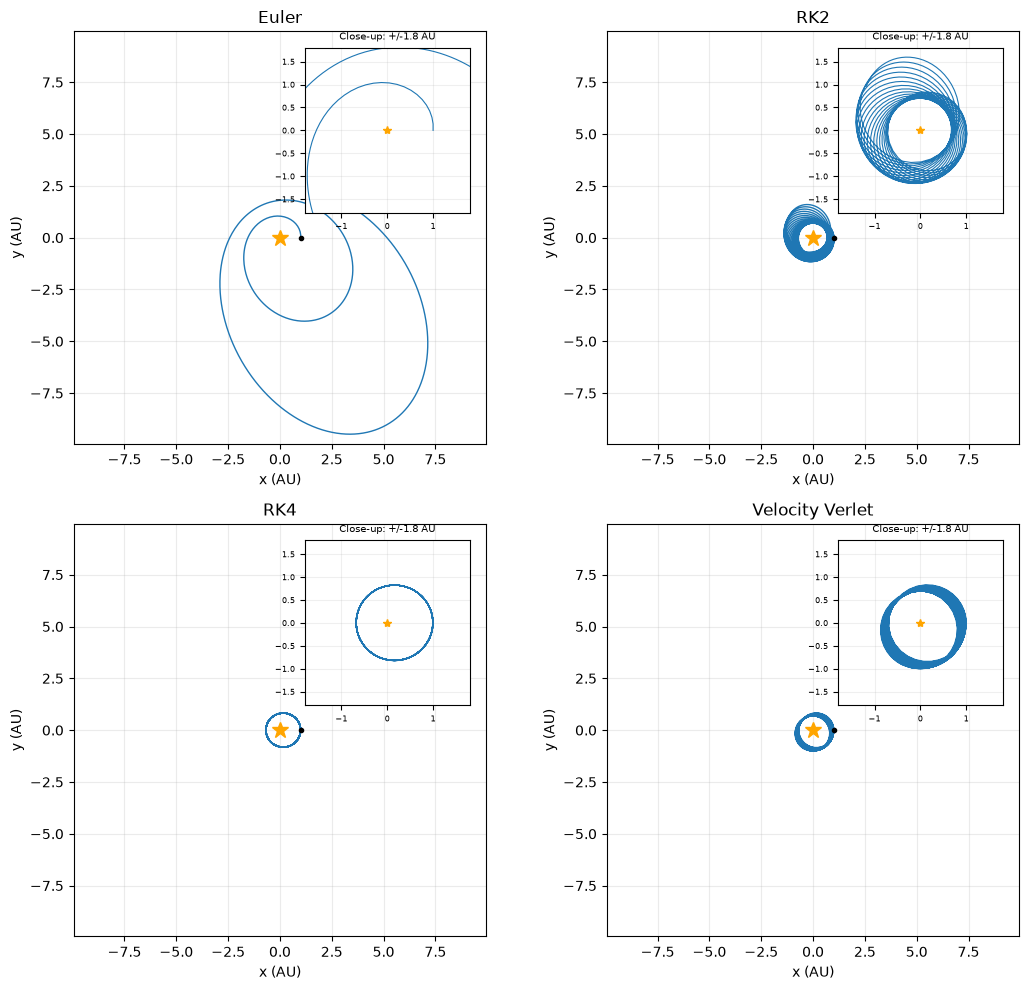

In [3]:
# Use a shared scale large enough to include EVERY saved position, including Euler's drift.
extent = 1.05*max(np.max(np.abs(path[:, :2])) for _, path in results.values())
fig, axes = plt.subplots(2, 2, figsize=(11, 10))

for ax, name in zip(axes.flat, methods):
    t, path = results[name]
    
    ax.plot(path[:, 0], path[:, 1], lw=1)
    ax.plot(0, 0, '*', ms=12, color='orange', label='Fixed star')
    ax.plot(path[0, 0], path[0, 1], 'ko', ms=3)
    ax.set(xlabel='x (AU)', ylabel='y (AU)', title=name,
           xlim=(-extent, extent), ylim=(-extent, extent))
    ax.set_aspect('equal')  # Equal axis scaling prevents a circle from looking elliptical.
    ax.grid(alpha=0.25)
    
    # A common close-up makes the smaller orbits visible without clipping the main view.
    inset = ax.inset_axes([0.56, 0.56, 0.40, 0.40])
    inset.plot(path[:, 0], path[:, 1], lw=0.8)
    inset.plot(0, 0, '*', ms=6, color='orange')
    inset.set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), title='Close-up: +/-1.8 AU')
    inset.set_aspect('equal')
    inset.tick_params(labelsize=6)
    inset.title.set_fontsize(7)
    inset.grid(alpha=0.2)

plt.tight_layout()
plt.show()


## Does the planet really gain energy?

In the continuous model, the specific energy $\varepsilon=v^2/2-\mu/r$ and specific angular momentum $\ell=xv_y-yv_x$ are constant. Plot $\Delta\varepsilon/|\varepsilon_0|$ and $\Delta\ell/|\ell_0|$. A systematic increase in energy comes from the numerical method: the model contains no motor or external force. Verlet can have a small bounded energy oscillation even though its energy is not exactly constant at each step. 

Velocity Verlet preserves angular momentum for this central force up to roundoff, while its energy can oscillate. The common vertical scale can hide small errors: use the printed energy deviations to compare RK4 and Verlet. Conserving energy or angular momentum does not by itself guarantee the correct orbital phase or orientation.

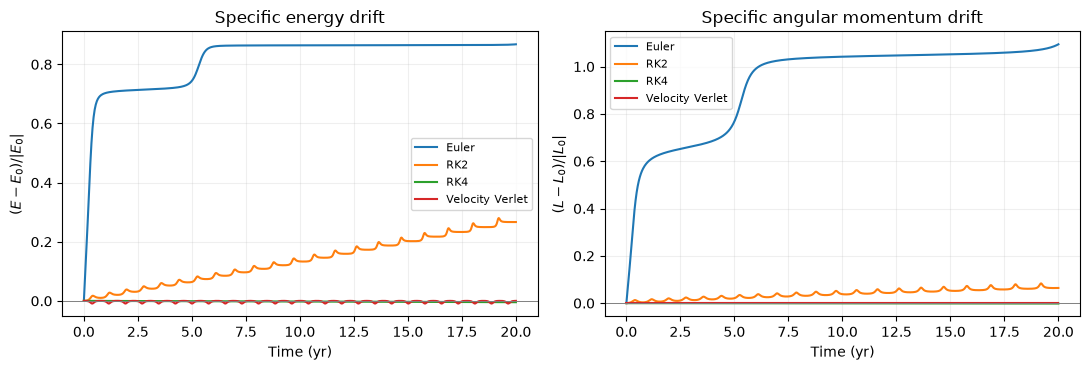

Euler            final relative energy change =  8.679e-01; maximum |relative energy change| = 8.679e-01
RK2              final relative energy change =  2.667e-01; maximum |relative energy change| = 2.801e-01
RK4              final relative energy change = -4.424e-03; maximum |relative energy change| = 4.424e-03
Velocity Verlet  final relative energy change = -1.245e-05; maximum |relative energy change| = 8.992e-03


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

for name in methods:
    t, path = results[name]
    
    # Evaluate conservation diagnostics at every saved state, not just the endpoint.
    E, L = invariants(path)
    
    # Dividing by |E0| preserves the sign of energy gain even though bound-orbit E0 is negative.
    axes[0].plot(t, (E-E[0])/abs(E[0]), label=name)
    axes[1].plot(t, (L-L[0])/abs(L[0]), label=name)

axes[0].set(xlabel='Time (yr)', ylabel=r'$(E-E_0)/|E_0|$', title='Specific energy drift')
axes[1].set(xlabel='Time (yr)', ylabel=r'$(L-L_0)/|L_0|$', title='Specific angular momentum drift')

for ax in axes:
    ax.axhline(0, color='gray', lw=0.7)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Final drift can partly cancel; the maximum absolute deviation checks the full run.
for name in methods:
    E, L = invariants(results[name][1])
    print(f'{name:16s} final relative energy change = {(E[-1]-E[0])/abs(E[0]): .3e}; '
          f'maximum |relative energy change| = {np.max(abs((E-E[0])/E[0])):.3e}')

## Step size and accuracy

Repeat an eight-year integration with three step sizes. The table records the *largest* energy deviation, including bounded oscillations, and final energy drift. A smaller final drift can sometimes result from cancellation; read both columns. The four methods use different numbers of force evaluations per step, so this is a comparison at equal step size, not equal computation cost.

In [5]:
# Fix physical duration at 8 years; halving h doubles the number of steps.
for h in [0.04, 0.02, 0.01]:
    print(f'\nh = {h} yr')
    
    for name in methods:
        _, path = orbit_path(name, h, 8)
        E, _ = invariants(path)
        
        # Peak deviation counts both secular drift and bounded oscillations.
        peak = np.max(abs((E-E[0])/E[0]))
        
        # Keep the sign to distinguish net artificial energy gain from loss.
        final = (E[-1]-E[0])/abs(E[0])
        print(f'{name:16s} max |dE/E0| = {peak:.3e}   final dE/|E0| = {final:+.3e}')


h = 0.04 yr
Euler            max |dE/E0| = 8.541e-01   final dE/|E0| = +8.541e-01
RK2              max |dE/E0| = 3.089e-01   final dE/|E0| = +2.888e-01
RK4              max |dE/E0| = 1.907e-02   final dE/|E0| = -1.907e-02
Velocity Verlet  max |dE/E0| = 1.955e-02   final dE/|E0| = -1.100e-02

h = 0.02 yr
Euler            max |dE/E0| = 8.124e-01   final dE/|E0| = +8.124e-01
RK2              max |dE/E0| = 6.581e-02   final dE/|E0| = +5.926e-02
RK4              max |dE/E0| = 5.546e-04   final dE/|E0| = -5.546e-04
Velocity Verlet  max |dE/E0| = 5.981e-03   final dE/|E0| = -3.302e-03

h = 0.01 yr
Euler            max |dE/E0| = 7.466e-01   final dE/|E0| = +7.466e-01
RK2              max |dE/E0| = 1.028e-02   final dE/|E0| = +9.351e-03
RK4              max |dE/E0| = 1.729e-05   final dE/|E0| = -1.708e-05
Velocity Verlet  max |dE/E0| = 1.577e-03   final dE/|E0| = -8.534e-04


## Conclusion

The same equations and initial state can produce visibly different orbits after repeated time steps. Energy and angular momentum give independent checks: Euler's artificial energy gain changes the orbit, while the higher-order methods and velocity Verlet control that error differently. The step-size table tests whether a visible effect persists when the discretization is refined.